# Task 3: Investigate Capacity and Regularization

Setup


In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import torch

from cifar_data import CLASS_NAMES, get_split, load_cifar10, make_test_loader
from models.alexnet import AlexNet
from models.resnet import ResNet18
from train import CHECKPOINT_DIR, Run, count_parameters, evaluate, get_device, run_experiment

RETRAIN = False                      # True = ignore saved checkpoints and train again
FIG_DIR = Path("figures/task2"); FIG_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_DIR = Path("results"); RESULTS_DIR.mkdir(exist_ok=True)

device = get_device()
NUM_WORKERS = 2 if device.type == "cuda" else 0

data = load_cifar10()
split = get_split(data["train"])
stats = split["stats"]
print(f"train {len(split['train_ids'])} | val {len(split['val_ids'])} | test {len(data['test'])}")
print("torch", torch.__version__, "| device", device,
      "|", torch.cuda.get_device_name(0) if device.type == "cuda" else "")

train 45000 | val 5000 | test 10000
torch 2.15.0+cu132 | device cuda | NVIDIA GeForce RTX 3060 Laptop GPU


Helper functions

In [2]:
def train_or_load(model_class, run):
    path = CHECKPOINT_DIR / f"{run.name}_seed{run.seed}.pt"
    if path.exists() and not RETRAIN:
        checkpoint = torch.load(path, map_location=device)
        model = model_class(**run.options).to(device)
        model.load_state_dict(checkpoint["state_dict"])
        print("loaded", path)
        return model, checkpoint["history"], checkpoint["summary"]
    return run_experiment(run, model_class, data, split, device, num_workers=NUM_WORKERS)


def run_group(experiments):
    results = {}
    for model_class, run in experiments:
        model, history, summary = train_or_load(model_class, run)
        results[run.name] = {"model": model, "history": history, "summary": summary}
    return results


def train_key(history):
    # eval-mode training metrics if train.py has the fix, otherwise the (dropout-on) training metrics
    return "train_eval" if "train_eval_accuracy" in history[0] else "train"


def plot_group(results, title):
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    for name, r in results.items():
        h = pd.DataFrame(r["history"])
        tk = train_key(r["history"])
        for ax, metric in zip(axes, ["ce", "accuracy"]):
            line, = ax.plot(h.epoch, h[f"{tk}_{metric}"], label=f"{name} train")
            ax.plot(h.epoch, h[f"val_{metric}"], "--", color=line.get_color(), label=f"{name} val")
    axes[0].set(xlabel="Epoch", ylabel="Cross-entropy", title="Loss (solid = train, dashed = val)")
    axes[1].set(xlabel="Epoch", ylabel="Accuracy", title="Accuracy (solid = train, dashed = val)")
    for ax in axes:
        ax.legend(fontsize=7)
    fig.suptitle(title)
    fig.tight_layout()
    fig.savefig(FIG_DIR / f"{title.replace(' ', '_').lower()}.png", dpi=150)
    plt.show()


def summary_table(results):
    rows = []
    for name, r in results.items():
        h = pd.DataFrame(r["history"])
        tk = train_key(r["history"])
        best = h.loc[h.val_accuracy.idxmax()]
        last = h.iloc[-1]
        rows.append({
            "run": name,
            "parameters": r["summary"]["parameters"],
            "best_epoch": int(best.epoch),
            "best_val_acc": best.val_accuracy,
            "train_acc_at_best": best[f"{tk}_accuracy"],
            "gap_at_best": best[f"{tk}_accuracy"] - best.val_accuracy,   # overfitting indicator
            "final_gap": last[f"{tk}_accuracy"] - last.val_accuracy,
            "min_val_ce": h.val_ce.min(),
            "final_val_ce": last.val_ce,                                   # > min_val_ce = val loss rising again
            "sec_per_epoch": r["summary"]["train_seconds"] / len(h),
            "peak_gpu_mb": r["summary"]["peak_gpu_mb"],
        })
    return pd.DataFrame(rows).set_index("run").round(4)

Dropout

[1/30] alexnet_dropout0.0 | train ce 2.160 acc 0.193 | val ce 1.808 acc 0.326 | 8.3s
[2/30] alexnet_dropout0.0 | train ce 1.581 acc 0.416 | val ce 1.400 acc 0.488 | 8.0s
[3/30] alexnet_dropout0.0 | train ce 1.327 acc 0.512 | val ce 1.222 acc 0.547 | 8.0s
[4/30] alexnet_dropout0.0 | train ce 1.128 acc 0.591 | val ce 1.064 acc 0.624 | 8.0s
[5/30] alexnet_dropout0.0 | train ce 0.971 acc 0.653 | val ce 0.927 acc 0.664 | 8.1s
[6/30] alexnet_dropout0.0 | train ce 0.837 acc 0.705 | val ce 0.830 acc 0.705 | 8.0s
[7/30] alexnet_dropout0.0 | train ce 0.737 acc 0.741 | val ce 0.790 acc 0.729 | 8.0s
[8/30] alexnet_dropout0.0 | train ce 0.655 acc 0.770 | val ce 0.674 acc 0.762 | 8.0s
[9/30] alexnet_dropout0.0 | train ce 0.567 acc 0.801 | val ce 0.670 acc 0.775 | 8.1s
[10/30] alexnet_dropout0.0 | train ce 0.499 acc 0.825 | val ce 0.620 acc 0.788 | 8.0s
[11/30] alexnet_dropout0.0 | train ce 0.432 acc 0.849 | val ce 0.660 acc 0.772 | 8.1s
[12/30] alexnet_dropout0.0 | train ce 0.367 acc 0.872 | val ce 

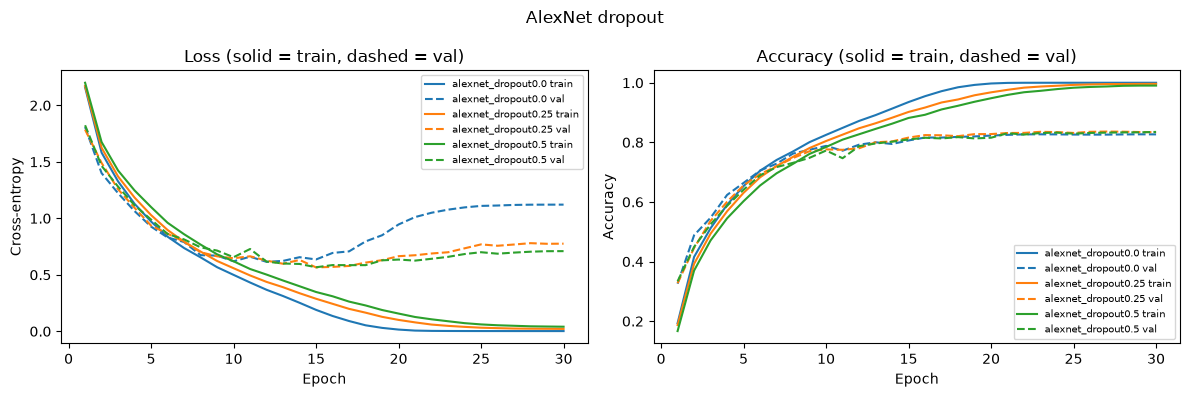

,parameters,best_epoch,best_val_acc,train_acc_at_best,gap_at_best,final_gap,min_val_ce,final_val_ce,sec_per_epoch,peak_gpu_mb
run,,,,,,,,,,
alexnet_dropout0.0,6976842,23,0.8270,1.0000,0.1730,0.1732,0.6148,1.1212,8.0897,271.8193
alexnet_dropout0.25,6976842,27,0.8362,0.9956,0.1594,0.1621,0.5656,0.7756,8.1466,326.1133
alexnet_dropout0.5,6976842,30,0.8350,0.9905,0.1555,0.1555,0.5668,0.7096,8.1453,382.7510


In [3]:
EPOCHS_B1 = 30
dropout_runs = run_group([
    (AlexNet, Run(f"alexnet_dropout{p}", epochs=EPOCHS_B1, lr=0.01, options={"dropout": p}))
    for p in [0.0, 0.25, 0.5]
])
plot_group(dropout_runs, "AlexNet dropout")
b1_table = summary_table(dropout_runs)
display(b1_table)
b1_table.to_csv(RESULTS_DIR / "task3_b1_dropout.csv")

L2 regularization

In [ ]:
EPOCHS_B2 = 15   # same budget as the Task 2 ResNet baseline
l2_runs = run_group([
    (ResNet18, Run(f"resnet18_l2_{l2}", epochs=EPOCHS_B2, lr=0.1, l2=l2))
    for l2 in [0.0, 5e-4, 5e-3]
])
plot_group(l2_runs, "ResNet-18 L2")

In [ ]:
def weight_norm(model):
    # squared L2 norm of conv and linear weights (dim > 1 skips BatchNorm and biases) - what A8's penalty sums over
    return sum(p.detach().square().sum().item() for p in model.parameters() if p.dim() > 1)

b2_table = summary_table(l2_runs)
b2_table["weight_norm_sq"] = [weight_norm(r["model"]) for r in l2_runs.values()]
display(b2_table)
b2_table.to_csv(RESULTS_DIR / "task3_b2_l2.csv")